# 06 · Modelo global LightGBM

Un solo modelo para todas las series detalladas. **Objetivo:** log del cambio respecto al último valor observado, `log1p(y[T+h]) − log1p(y[T])`. **Variables:** último valor (log), cambios de 1 y 2 años, medias móviles de 3 y 5 años, % de ceros recientes, longitud de la historia, distancia al máximo, horizonte, año, producto y municipio (categóricas); ONI con rezago si `usar_oni: true`.

Se valida con **el mismo walk-forward** que los baselines (cada modelo solo ve filas cuyo año objetivo es ≤ origen: sin fugas).

In [1]:
import os, sys
from pathlib import Path
from importlib import import_module

ROOT = Path.cwd().resolve()
while not (ROOT / "config/ML_C/parametros.yaml").exists():
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src/ML_C"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from common import CFG, RAW, CLEAN, RES
from graficos import estilo, COLORES
estilo(); pd.set_option("display.max_columns", 30, "display.width", 160)

In [2]:
REENTRENAR = False   # True vuelve a correr 06_lgbm.py (requiere lightgbm)
if REENTRENAR:
    import_module("06_lgbm").main()
comp = pd.read_csv(RES / "predicciones_comparacion.csv", dtype={"cod_dane": str})
comp["naive_lgbm"] = (comp.naive + comp.lgbm) / 2
b5 = import_module("05_baselines")
met = b5.metricas(comp, modelos=("naive", "naive_lgbm", "lgbm", "drift", "ets", "mean5"))
nombres = {"naive": "Ingenuo", "naive_lgbm": "Promedio ingenuo + LightGBM", "lgbm": "LightGBM", "drift": "Deriva", "ets": "ETS amortiguado", "mean5": "Promedio 5 años"}
tot = met[met.producto == "TOTAL"].set_index("modelo").rename(index=nombres)[["n_obs", "MASE", "WAPE", "mejora_MASE_vs_naive", "mejora_WAPE_vs_naive"]]
tot.sort_values("MASE").round(3)

,n_obs,MASE,WAPE,mejora_MASE_vs_naive,mejora_WAPE_vs_naive
modelo,,,,,
Promedio ingenuo + LightGBM,8323,3.899,0.101,0.005,-0.001
LightGBM,8323,3.904,0.103,0.003,-0.019
Ingenuo,8323,3.918,0.101,0.000,0.000
Deriva,8323,4.049,0.106,-0.033,-0.051
ETS amortiguado,8323,4.212,0.131,-0.075,-0.295
Promedio 5 años,8323,4.291,0.150,-0.095,-0.485


In [3]:
pp = met[(met.producto != "TOTAL") & (met.modelo == "lgbm")].set_index("producto")
gana = (pp.mejora_MASE_vs_naive > 0) & (pp.mejora_WAPE_vs_naive > 0)
print(f"LightGBM mejora MASE y WAPE a la vez en {gana.sum()} de {len(pp)} productos")
pp[["MASE", "WAPE", "mejora_MASE_vs_naive", "mejora_WAPE_vs_naive"]].round(3).sort_values("mejora_MASE_vs_naive", ascending=False)

LightGBM mejora MASE y WAPE a la vez en 12 de 22 productos


,MASE,WAPE,mejora_MASE_vs_naive,mejora_WAPE_vs_naive
producto,,,,
Ají,2.123,0.613,0.139,0.097
Cítricos,3.245,0.256,0.096,0.028
Yuca,1.779,0.666,0.070,0.096
Cebolla Larga,1.401,1.229,0.054,0.011
Maracuyá,1.479,0.481,0.042,0.108
Papaya,1.359,0.591,0.039,0.094
Café,1.273,0.468,0.035,0.036
Lulo,2.284,0.378,0.024,0.019
Mango,3.197,0.457,0.024,0.032


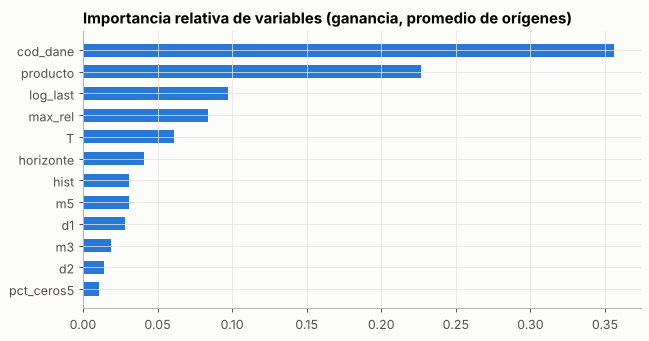

In [4]:
imp = pd.read_csv(RES / "importancia_variables.csv").sort_values("importancia_relativa")
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(imp.variable, imp.importancia_relativa, color=COLORES[0], height=0.6)
ax.set_title("Importancia relativa de variables (ganancia, promedio de orígenes)")
plt.show()

## Experimento ONI

El ONI futuro no se conoce, por eso solo entra como valor **rezagado** (año T y T−1). El experimento compara LightGBM con y sin ONI sobre las mismas filas y guarda `metricas_oni.csv`. Si mejora, se cambia `usar_oni: true` en `config/ML_C/parametros.yaml` y se vuelven a correr 06 y 07.

In [5]:
EJECUTAR_ONI = False   # True corre el experimento (requiere lightgbm, ~1 min)
if EJECUTAR_ONI:
    import_module("06_lgbm").comparar_oni()
f = RES / "metricas_oni.csv"
pd.read_csv(f) if f.exists() else print("Aún no se ha corrido el experimento ONI (python src/ML_C/06_lgbm.py --comparar-oni).")

Aún no se ha corrido el experimento ONI (python src/ML_C/06_lgbm.py --comparar-oni).


**Lectura.** LightGBM queda en **empate técnico** con el ingenuo (MASE +0,3 %, WAPE −1,9 %) y solo mejora ambas métricas en una parte de los productos, con márgenes pequeños. Se reporta así, sin venderlo como mejora. Para la oferta base se usa el **promedio ingenuo + LightGBM** en los detallados (el de menor MASE, con WAPE igual al ingenuo) y el ingenuo en los simplificados.